# Meme sentiment classification using images and text

This project looks at whether using both the image and text in a meme improves sentiment classification. The task is to predict one of three labels: **negative, neutral or positive**.

I compare image-only and text-only models with two ways of combining them: early fusion and late fusion. I also include a majority-class baseline and TF-IDF with Logistic Regression. I use **macro F1** as the main score because the sentiment classes are not evenly distributed.

The dataset is [Memotion 7K on Kaggle](https://www.kaggle.com/datasets/williamscott701/memotion-dataset-7k/data). Pretrained ResNet-50 and DistilBERT are used to extract features; only the classification layers are trained. Model selection uses validation results, followed by a test-set comparison.

The models and settings below are those used for the final Experiment 5 configuration. Earlier experiments are discussed separately in the report.


## 0. Setup

This notebook was developed using Python, PyTorch and an NVIDIA GPU. Install the packages once if they are missing, then restart the Jupyter kernel. The same code can run on CPU, but feature extraction will be slower.


In [3]:
# Install dependencies once if needed, then restart the kernel:
#pip install numpy pandas matplotlib seaborn scikit-learn pillow tqdm torchvision transformers accelerate safetensors sentencepiece joblib

import sys
import platform
import torch
print('Python:', sys.version.split()[0])
print('System:', platform.platform())
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))


Note: you may need to restart the kernel to use updated packages.
Python: 3.12.7
System: Windows-11-10.0.26200-SP0
PyTorch: 2.7.1+cu118
CUDA available: True
GPU: NVIDIA GeForce RTX 3070 Laptop GPU


## 1. Settings and random seed

Set the dataset location here. I use the same random seed and data split for the model comparisons. The notebook saves outputs in a separate folder and reuses cached image and text features when they are available.


In [5]:
from pathlib import Path
import os, random, json, time, hashlib, warnings, copy
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, UnidentifiedImageError
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, classification_report, confusion_matrix
import torch
import transformers
from torch import nn
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torchvision import models
from transformers import AutoTokenizer, AutoModel

# Windows example: Path(r'C:\Users\YourName\Downloads\memotion_dataset_7k')
DATA_DIR = Path(
    os.environ.get('MEMOTION_DATA_DIR', 'dataset')
).resolve()

# Reuse the already extracted image and text embeddings
# Save final experiment outputs separately
OUTPUT_DIR = Path('outputs_final')

# Reuse cached image and text embeddings
CACHE_DIR = Path('outputs/cache')

for folder in (OUTPUT_DIR, CACHE_DIR):
    folder.mkdir(parents=True, exist_ok=True)
SEED = 42
IMAGE_BATCH_SIZE = 32  # if CUDA out of memory, try 8 or 16
TEXT_BATCH_SIZE = 16   # if CUDA out of memory, try 8
MLP_BATCH_SIZE = 64
MAX_TEXT_LENGTH = 128
EPOCHS = 35
PATIENCE = 6
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_WORKERS = 0  # reliable in Windows Jupyter; tune later if desired
LABEL_NAMES = ['negative', 'neutral', 'positive']
LABEL_TO_ID = {x:i for i,x in enumerate(LABEL_NAMES)}
def seed_all(seed=42):
    import os
    import random
    import numpy as np
    import torch

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Prefer deterministic CuDNN operations
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    print(f"Random seed set to: {seed}")
seed_all(SEED)
print('Device:', DEVICE, '| Data folder:', DATA_DIR.resolve())

Random seed set to: 42
Device: cuda | Data folder: C:\Users\joech\MultiModal\dataset


## 2. Dataset checks and cleaning

The Memotion 7K labels include five sentiment levels. I combine *very negative* with *negative* and *very positive* with *positive* to match the three-class task.

For text, I use the corrected version when it is available and otherwise fall back to the OCR text. I check for missing and unreadable images, then remove exact duplicate image files. This also helps avoid putting identical images in different splits. Similar-looking memes and differences in annotation remain possible limitations.


In [7]:
if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATA_DIR}\n"
        "Download the Memotion Dataset 7K from Kaggle "
        "and extract it inside the dataset folder.\n"
        "See README.md for instructions."
    )
label_paths = sorted([p for p in DATA_DIR.rglob('*') if p.is_file() and p.name.lower() in ('labels.csv','labels.xlsx')], key=lambda p:(p.suffix != '.csv',len(p.parts)))
if not label_paths:
    raise FileNotFoundError('Could not locate labels.csv or labels.xlsx in DATA_DIR. Inspect your extracted Kaggle folder.')
label_path = label_paths[0]
raw = pd.read_csv(label_path, encoding='utf-8-sig') if label_path.suffix.lower()=='.csv' else pd.read_excel(label_path)
raw.columns = raw.columns.astype(str).str.strip().str.lower()
print('Metadata:', label_path, '\nRaw shape:', raw.shape, '\nColumns:', raw.columns.tolist())
display(raw.head(3))
required = {'image_name','overall_sentiment'}
if not required.issubset(raw.columns):
    raise ValueError(f'Missing required columns: {required-set(raw.columns)}. Available: {raw.columns.tolist()}')
print('Raw sentiment labels:')
display(raw['overall_sentiment'].astype(str).str.strip().str.lower().value_counts(dropna=False))
print('Missing metadata values:')
display(raw.isna().sum().sort_values(ascending=False).head(15))

Metadata: C:\Users\joech\MultiModal\dataset\memotion_dataset_7k\labels.csv 
Raw shape: (6992, 9) 
Columns: ['unnamed: 0', 'image_name', 'text_ocr', 'text_corrected', 'humour', 'sarcasm', 'offensive', 'motivational', 'overall_sentiment']


,unnamed: 0,image_name,text_ocr,text_corrected,humour,sarcasm,offensive,motivational,overall_sentiment
0,0,image_1.jpg,LOOK THERE MY FRIEND LIGHTYEAR NOW ALL SOHALIK...,LOOK THERE MY FRIEND LIGHTYEAR NOW ALL SOHALIK...,hilarious,general,not_offensive,not_motivational,very_positive
1,1,image_2.jpeg,The best of #10 YearChallenge! Completed in le...,The best of #10 YearChallenge! Completed in le...,not_funny,general,not_offensive,motivational,very_positive
2,2,image_3.JPG,Sam Thorne @Strippin ( Follow Follow Saw every...,Sam Thorne @Strippin ( Follow Follow Saw every...,very_funny,not_sarcastic,not_offensive,not_motivational,positive


Raw sentiment labels:


overall_sentiment
positive         3127
neutral          2201
very_positive    1033
negative          480
very_negative     151
Name: count, dtype: int64

Missing metadata values:


text_ocr             161
text_corrected         5
unnamed: 0             0
image_name             0
humour                 0
sarcasm                0
offensive              0
motivational           0
overall_sentiment      0
dtype: int64

Unrecognized/missing target labels: 0
Image files discovered: 6991
Missing image matches: 1


Checking image integrity: 100%|████████████████████████████████| 6991/6991 [00:03<00:00, 2101.05it/s]

{'raw_rows': 6992, 'usable_rows': 6965, 'missing_images': 1, 'corrupt_image_rows': 1, 'exact_duplicates_removed': 25, 'duplicate_groups_with_conflicting_labels': 11, 'empty_text': 4}


sentiment
negative     628
neutral     2196
positive    4141
Name: count, dtype: int64

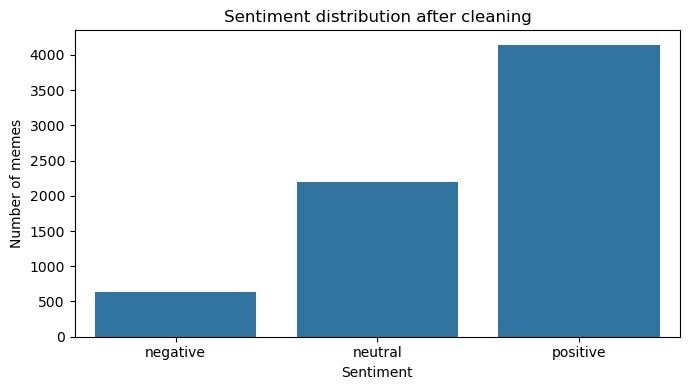

In [8]:
df = raw.copy()
label_clean = (df['overall_sentiment'].astype('string').str.strip().str.lower()
    .str.replace(r'[\s\-]+','_',regex=True))
label_map = {'very_negative':'negative','negative':'negative','neutral':'neutral',
             'positive':'positive','very_positive':'positive'}
df['sentiment'] = label_clean.map(label_map)
print('Unrecognized/missing target labels:', int(df['sentiment'].isna().sum()))
df = df.dropna(subset=['sentiment','image_name']).copy()
for col in ('text_corrected','text_ocr'):
    if col not in df: df[col] = ''
    df[col] = df[col].fillna('').astype(str).str.strip()
# Do not use dataset labels or other ground-truth metadata as text features.
df['text'] = df['text_corrected'].where(df['text_corrected'].ne(''),df['text_ocr'])
df['image_name'] = df['image_name'].astype(str).str.strip()
# Case-insensitive filename lookup for Windows-friendly robust matching.
image_files = [p for p in DATA_DIR.rglob('*') if p.is_file() and p.suffix.lower() in ('.jpg','.jpeg','.png','.webp','.bmp')]
image_index = {}
for path in image_files:
    image_index.setdefault(path.name.lower(),path)
print('Image files discovered:',len(image_files))
df['image_path'] = df['image_name'].str.lower().map(image_index)
missing_images = int(df['image_path'].isna().sum())
print('Missing image matches:',missing_images)
df = df.dropna(subset=['image_path']).copy()
# For modest dataset sizes, validate all images and compute exact-image hashes for leakage prevention.
def read_image_hash(path):
    try:
        with Image.open(path) as im:
            im.verify()
        with open(path,'rb') as f:
            return hashlib.sha256(f.read()).hexdigest()
    except (OSError, ValueError, UnidentifiedImageError):
        return None
unique_paths = df['image_path'].unique()
hashes = {p:read_image_hash(p) for p in tqdm(unique_paths,desc='Checking image integrity')}
df['image_hash'] = df['image_path'].map(hashes)
corrupt = int(df['image_hash'].isna().sum())
df = df.dropna(subset=['image_hash']).copy()
# Discard duplicated image bytes; inconsistent labels on duplicate images are an annotation-quality concern.
conflicting = int((df.groupby('image_hash')['sentiment'].nunique()>1).sum())
removed_duplicates = int(df.duplicated('image_hash').sum())
df = df.drop_duplicates(subset=['image_hash'],keep='first').reset_index(drop=True)
df['label'] = df['sentiment'].map(LABEL_TO_ID).astype(int)
assert df['label'].notna().all()
print({'raw_rows':len(raw),'usable_rows':len(df),'missing_images':missing_images,
       'corrupt_image_rows':corrupt,'exact_duplicates_removed':removed_duplicates,
       'duplicate_groups_with_conflicting_labels':conflicting,'empty_text':int(df.text.eq('').sum())})
display(df['sentiment'].value_counts().reindex(LABEL_NAMES))
fig,ax=plt.subplots(figsize=(7,4))
sns.countplot(data=df,x='sentiment',order=LABEL_NAMES,ax=ax)
ax.set(title='Sentiment distribution after cleaning',xlabel='Sentiment',ylabel='Number of memes')
plt.tight_layout(); plt.savefig(OUTPUT_DIR/'class_distribution.png',dpi=180); plt.show()

**Data quality note:** Exact file hashes detect identical image files, not resized or slightly edited copies. Duplicate memes with conflicting labels are a sign that sentiment can be subjective. These issues are considered when discussing the results.


## 3. Train, validation and test split

I use a stratified 70/15/15 split so each subset has roughly the same class proportions. The training set is used to fit the models, the validation set to choose settings and checkpoints, and the test set to compare the final models. The split details are saved to a CSV file.


In [11]:
if df['label'].value_counts().min() < 3:
    raise ValueError('Too few examples in a class for stratified splitting.')
idx = np.arange(len(df))
train_idx, temp_idx = train_test_split(idx,test_size=0.30,random_state=SEED,stratify=df['label'])
val_idx, test_idx = train_test_split(temp_idx,test_size=0.50,random_state=SEED,stratify=df.iloc[temp_idx]['label'])
df['split']=''
for name, ids in [('train',train_idx),('val',val_idx),('test',test_idx)]:df.loc[ids,'split']=name
assert df.groupby('image_hash')['split'].nunique().max()==1
assert set(train_idx).isdisjoint(val_idx) and set(train_idx).isdisjoint(test_idx) and set(val_idx).isdisjoint(test_idx)
manifest = df[['image_name','image_hash','text','sentiment','label','split']].copy()
manifest.to_csv(OUTPUT_DIR/'split_manifest.csv',index=False)
display(pd.crosstab(df['split'],df['sentiment']).reindex(index=['train','val','test'],columns=LABEL_NAMES))
print('Split manifest saved:',OUTPUT_DIR/'split_manifest.csv')

sentiment,negative,neutral,positive
split,,,
train,440,1537,2898
val,94,329,622
test,94,330,621


Split manifest saved: outputs_final\split_manifest.csv


## 4. Image features: ResNet-50

I use a pretrained ResNet-50 model without its final classification layer. Each meme is converted to RGB and processed using the transforms supplied with the model weights. This gives 2,048 image features per meme. The ResNet-50 weights remain frozen.


In [13]:
from torchvision.models import ResNet50_Weights
weights = ResNet50_Weights.DEFAULT
image_transform = weights.transforms()
class MemeImageDataset(Dataset):
    def __init__(self, frame): self.frame=frame.reset_index(drop=True)
    def __len__(self): return len(self.frame)
    def __getitem__(self,i):
        with Image.open(self.frame.loc[i,'image_path']) as im:
            image = image_transform(im.convert('RGB'))
        return image

@torch.inference_mode()
def compute_image_embeddings(frame):
    model=models.resnet50(weights=weights)
    model.fc=nn.Identity()
    model=model.to(DEVICE).eval()
    loader=DataLoader(MemeImageDataset(frame),batch_size=IMAGE_BATCH_SIZE,shuffle=False,
                      num_workers=NUM_WORKERS,pin_memory=(DEVICE.type=='cuda'))
    parts=[]
    for images in tqdm(loader,desc='ResNet-50 image embeddings'):
        feats=model(images.to(DEVICE,non_blocking=True))
        parts.append(feats.float().cpu())
    result=torch.cat(parts).numpy()
    del model
    if DEVICE.type=='cuda':torch.cuda.empty_cache()
    return result

# Cache keys reflect the exact split rows and configuration; delete cache after changing model versions.
signature = hashlib.sha256(('\n'.join(df.image_hash.astype(str)) + str(weights)).encode()).hexdigest()[:12]
image_cache=CACHE_DIR/f'image_resnet50_{signature}.npy'
if image_cache.exists():
    X_image=np.load(image_cache)
    print('Loaded cached image embeddings:',image_cache)
else:
    X_image=compute_image_embeddings(df)
    np.save(image_cache,X_image)
print('Image embeddings:',X_image.shape)
assert X_image.shape==(len(df),2048)

Loaded cached image embeddings: outputs\cache\image_resnet50_0296d3c1b3a1.npy
Image embeddings: (6965, 2048)


## 5. Text features: DistilBERT

I extract text features using pretrained DistilBERT. The text is tokenised and limited to 128 tokens. I average the token representations while ignoring padding, giving 768 text features per meme. DistilBERT is also kept frozen.


In [15]:
TEXT_MODEL_ID='distilbert-base-uncased'
@torch.inference_mode()
def compute_text_embeddings(texts):
    tokenizer=AutoTokenizer.from_pretrained(TEXT_MODEL_ID)
    model=AutoModel.from_pretrained(TEXT_MODEL_ID).to(DEVICE).eval()
    results=[]
    for start in tqdm(range(0,len(texts),TEXT_BATCH_SIZE),desc='DistilBERT text embeddings'):
        batch=texts[start:start+TEXT_BATCH_SIZE]
        tokens=tokenizer(batch,padding=True,truncation=True,max_length=MAX_TEXT_LENGTH,return_tensors='pt')
        tokens={k:v.to(DEVICE) for k,v in tokens.items()}
        outputs=model(**tokens).last_hidden_state
        mask=tokens['attention_mask'].unsqueeze(-1)
        pooled=(outputs*mask).sum(dim=1)/mask.sum(dim=1).clamp(min=1)
        results.append(pooled.float().cpu())
    embeddings=torch.cat(results).numpy()
    del model
    if DEVICE.type=='cuda':torch.cuda.empty_cache()
    return embeddings
text_signature=hashlib.sha256(('\n'.join(df.text.tolist())+TEXT_MODEL_ID+str(MAX_TEXT_LENGTH)).encode()).hexdigest()[:12]
text_cache=CACHE_DIR/f'text_distilbert_{text_signature}.npy'
if text_cache.exists():
    X_text=np.load(text_cache)
    print('Loaded cached text embeddings:',text_cache)
else:
    X_text=compute_text_embeddings(df.text.tolist())
    np.save(text_cache,X_text)
print('Text embeddings:',X_text.shape)
assert X_text.shape==(len(df),768)

Loaded cached text embeddings: outputs\cache\text_distilbert_e716e78c61ae.npy
Text embeddings: (6965, 768)


## 6. Preparing features and classifiers

I standardise the image and text features using statistics calculated from the training set only. Early fusion joins the two feature vectors before sending them to an MLP. All three neural classifiers use hidden layers of 128 and 32 units, dropout of 0.40 and a three-class output.

The models are trained using AdamW and square-root class-weighted cross-entropy. I monitor validation macro F1 and save the best checkpoint using early stopping.


In [17]:
from sklearn.preprocessing import StandardScaler
image_scaler=StandardScaler().fit(X_image[train_idx]); text_scaler=StandardScaler().fit(X_text[train_idx])
Xi=image_scaler.transform(X_image).astype('float32')
Xt=text_scaler.transform(X_text).astype('float32')
Xf=np.concatenate([Xi,Xt],axis=1)
y=df['label'].to_numpy(dtype=np.int64)
views={'Image-only':Xi,'Text-only':Xt,'Early fusion':Xf}

train_counts=np.bincount(y[train_idx],minlength=3)
class_weights = np.sqrt(
    len(train_idx) / (3 * np.maximum(train_counts, 1))
).astype('float32')

print(
    'Class counts:', train_counts,
    '| New class weights:', class_weights
)


class MLPClassifier(nn.Module):
    def __init__(self, in_dim, hidden=128, dropout=0.40, num_classes=3):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden, 32),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        return self.net(x)

def as_loader(X, indices, shuffle=False):
    ds=TensorDataset(torch.from_numpy(X[indices]),torch.from_numpy(y[indices]))
    return DataLoader(ds,batch_size=MLP_BATCH_SIZE,shuffle=shuffle,num_workers=0,
                      pin_memory=(DEVICE.type=='cuda'))

@torch.inference_mode()
def get_probs(model,loader):
    model.eval(); probabilities=[]; targets=[]
    for xb,yb in loader:
        logits=model(xb.to(DEVICE))
        probabilities.append(logits.softmax(dim=1).cpu().numpy())
        targets.append(yb.numpy())
    return np.vstack(probabilities),np.concatenate(targets)

def fit_classifier(X,name):
    seed_all(SEED)
    net=MLPClassifier(X.shape[1]).to(DEVICE)
    opt = torch.optim.AdamW(net.parameters(),lr=3e-4,weight_decay=5e-3)
    criterion = nn.CrossEntropyLoss(
    weight=torch.as_tensor(
        class_weights,
        dtype=torch.float32,
        device=DEVICE
    ))
    train_loader=as_loader(X,train_idx,shuffle=True)
    train_eval_loader=as_loader(X,train_idx)
    val_loader=as_loader(X,val_idx)
    history=[]; best_score=-1; best_state=None; best_epoch=0; stale=0
    start=time.perf_counter()
    for epoch in range(1,EPOCHS+1):
        net.train(); total_loss=0; total_n=0
        for xb,yb in train_loader:
            xb=xb.to(DEVICE); yb=yb.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss=criterion(net(xb),yb)
            loss.backward(); opt.step()
            total_loss+=loss.item()*len(yb); total_n+=len(yb)
        p_train,y_train=get_probs(net,train_eval_loader)
        p_val,y_val=get_probs(net,val_loader)
        # Include the true validation loss (not merely the training loss).
        val_loss=0; val_n=0
        net.eval()
        with torch.inference_mode():
            for xb,yb in val_loader:
                loss=criterion(net(xb.to(DEVICE)),yb.to(DEVICE))
                val_loss+=loss.item()*len(yb);val_n+=len(yb)
        tr_f1=f1_score(y_train,p_train.argmax(1),average='macro',zero_division=0)
        va_f1=f1_score(y_val,p_val.argmax(1),average='macro',zero_division=0)
        history.append({'epoch':epoch,'train_loss':total_loss/total_n,'val_loss':val_loss/val_n,
                        'train_macro_f1':tr_f1,'val_macro_f1':va_f1})
        print(f'{name:12s} epoch {epoch:02d} | train F1={tr_f1:.3f} | val F1={va_f1:.3f}')
        if va_f1>best_score+1e-5:
            best_score=va_f1;best_epoch=epoch;best_state=copy.deepcopy(net.state_dict());stale=0
        else:
            stale+=1
            if stale>=PATIENCE:break
    net.load_state_dict(best_state)
    elapsed=time.perf_counter()-start
    torch.save({'state_dict':net.cpu().state_dict(),'input_dim':X.shape[1],'best_epoch':best_epoch,
                'seed':SEED,'label_names':LABEL_NAMES},OUTPUT_DIR/(name.lower().replace(' ','_')+'.pt'))
    net.to(DEVICE)
    return net,pd.DataFrame(history),{'training_seconds':elapsed,'best_epoch':best_epoch,'best_val_macro_f1':best_score}


Class counts: [ 440 1537 2898] | New class weights: [1.9217653 1.0282288 0.7488201]


## 7. Training the neural classifiers

I train three separate classifiers: image-only, text-only and early fusion. The pretrained feature extractors are not updated during this stage. I save the training history and the best validation checkpoint for each classifier.


In [19]:
trained={}; histories={}; training_info={}
for model_name, features in views.items():
    print('\n=== Training:',model_name,'===')
    trained[model_name],histories[model_name],training_info[model_name]=fit_classifier(features,model_name)
    histories[model_name].to_csv(OUTPUT_DIR/(model_name.lower().replace(' ','_')+'_history.csv'),index=False)
print('\nBest validation epochs:')
display(pd.DataFrame(training_info).T)


=== Training: Image-only ===
Random seed set to: 42
Image-only   epoch 01 | train F1=0.298 | val F1=0.264
Image-only   epoch 02 | train F1=0.350 | val F1=0.266
Image-only   epoch 03 | train F1=0.394 | val F1=0.278
Image-only   epoch 04 | train F1=0.504 | val F1=0.292
Image-only   epoch 05 | train F1=0.604 | val F1=0.302
Image-only   epoch 06 | train F1=0.739 | val F1=0.312
Image-only   epoch 07 | train F1=0.817 | val F1=0.319
Image-only   epoch 08 | train F1=0.846 | val F1=0.319
Image-only   epoch 09 | train F1=0.887 | val F1=0.322
Image-only   epoch 10 | train F1=0.904 | val F1=0.338
Image-only   epoch 11 | train F1=0.924 | val F1=0.326
Image-only   epoch 12 | train F1=0.946 | val F1=0.344
Image-only   epoch 13 | train F1=0.956 | val F1=0.326
Image-only   epoch 14 | train F1=0.966 | val F1=0.335
Image-only   epoch 15 | train F1=0.976 | val F1=0.318
Image-only   epoch 16 | train F1=0.978 | val F1=0.315
Image-only   epoch 17 | train F1=0.978 | val F1=0.320
Image-only   epoch 18 | train

,training_seconds,best_epoch,best_val_macro_f1
Image-only,5.761426,12.0,0.344102
Text-only,7.000622,16.0,0.361601
Early fusion,9.023966,20.0,0.347085


## 8. Late fusion

Late fusion combines the predicted probabilities from the image-only and text-only classifiers. I try different image weights on the validation set and keep the one with the highest macro F1. The selected weight is then used for the test comparison.


Best validation alpha (image weight): 0.00; text weight: 1.00


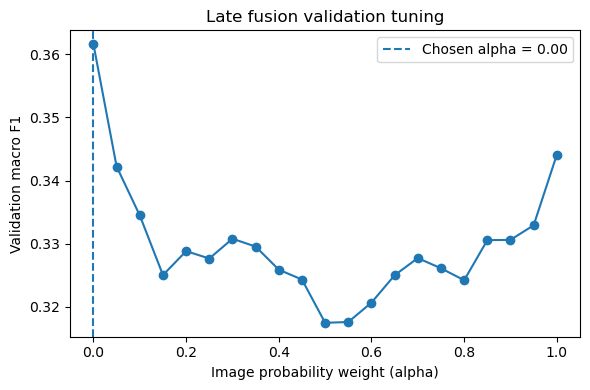

In [21]:
val_probs={}
for name in ('Image-only','Text-only'):
    val_probs[name], truth=get_probs(trained[name],as_loader(views[name],val_idx))
    assert np.array_equal(truth,y[val_idx])
alpha_scores=[]
for a in np.linspace(0,1,21):
    pred=(a*val_probs['Image-only']+(1-a)*val_probs['Text-only']).argmax(axis=1)
    alpha_scores.append({'alpha_image':float(a),'val_macro_f1':f1_score(y[val_idx],pred,average='macro',zero_division=0)})
alpha_table=pd.DataFrame(alpha_scores)
# Tie preference near 0.5 (a less extreme fusion) for a deterministic rule.
alpha_table['distance_from_half']=(alpha_table.alpha_image-0.5).abs()
best_row=alpha_table.sort_values(['val_macro_f1','distance_from_half'],ascending=[False,True]).iloc[0]
BEST_ALPHA=float(best_row.alpha_image)
alpha_table.drop(columns='distance_from_half').to_csv(OUTPUT_DIR/'late_fusion_alpha_search.csv',index=False)
print(f'Best validation alpha (image weight): {BEST_ALPHA:.2f}; text weight: {1-BEST_ALPHA:.2f}')
fig,ax=plt.subplots(figsize=(6,4))
ax.plot(alpha_table.alpha_image,alpha_table.val_macro_f1,marker='o')
ax.axvline(BEST_ALPHA,linestyle='--',label=f'Chosen alpha = {BEST_ALPHA:.2f}')
ax.set(xlabel='Image probability weight (alpha)',ylabel='Validation macro F1',title='Late fusion validation tuning')
ax.legend();plt.tight_layout();plt.savefig(OUTPUT_DIR/'late_fusion_alpha.png',dpi=180);plt.show()

## 9. Test-set comparison

I evaluate the trained neural classifiers and the selected late-fusion combination on the held-out test set. I report accuracy, macro F1, weighted F1, precision and recall.

**Evaluation note:** Earlier exploratory runs were also inspected using this same test split. The test results are therefore useful for comparing the recorded experiments, but they should not be described as an entirely independent assessment after all tuning decisions.


In [23]:
test_probs={}
for name in views:
    probs,test_truth=get_probs(trained[name],as_loader(views[name],test_idx))
    assert np.array_equal(test_truth,y[test_idx])
    test_probs[name]=probs

test_probs['Late fusion']=BEST_ALPHA*test_probs['Image-only']+(1-BEST_ALPHA)*test_probs['Text-only']

def calculate_metrics(name,probs):
    pred=probs.argmax(axis=1)
    return {'model':name,'accuracy':accuracy_score(test_truth,pred),
            'macro_f1':f1_score(test_truth,pred,average='macro',zero_division=0),
            'weighted_f1':f1_score(test_truth,pred,average='weighted',zero_division=0),
            'macro_precision':precision_recall_fscore_support(test_truth,pred,average='macro',zero_division=0)[0],
            'macro_recall':precision_recall_fscore_support(test_truth,pred,average='macro',zero_division=0)[1],
            'head_training_seconds':training_info.get(name,{}).get('training_seconds',0.0)}
results=pd.DataFrame([calculate_metrics(k,v) for k,v in test_probs.items()]).sort_values('macro_f1',ascending=False)
results.to_csv(OUTPUT_DIR/'test_model_comparison.csv',index=False)
display(results.round(4))
for name,probs in test_probs.items():
    print('\n',name,'\n',classification_report(test_truth,probs.argmax(1),target_names=LABEL_NAMES,labels=np.arange(3),zero_division=0))
    pd.DataFrame(classification_report(test_truth,probs.argmax(1),target_names=LABEL_NAMES,
        labels=np.arange(3),zero_division=0,output_dict=True)).T.to_csv(OUTPUT_DIR/(name.lower().replace(' ','_')+'_class_report.csv'))
np.savez_compressed(OUTPUT_DIR/'test_predictions.npz',y_true=test_truth,
                    **{k.lower().replace(' ','_'):v for k,v in test_probs.items()})

,model,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall,head_training_seconds
0,Image-only,0.4938,0.3452,0.4828,0.3475,0.3458,5.7614
2,Early fusion,0.5110,0.3387,0.4875,0.3449,0.3429,9.0240
1,Text-only,0.5129,0.3365,0.4765,0.3551,0.3421,7.0006
3,Late fusion,0.5129,0.3365,0.4765,0.3551,0.3421,0.0000



 Image-only 
               precision    recall  f1-score   support

    negative       0.11      0.07      0.09        94
     neutral       0.33      0.31      0.32       330
    positive       0.61      0.66      0.63       621

    accuracy                           0.49      1045
   macro avg       0.35      0.35      0.35      1045
weighted avg       0.47      0.49      0.48      1045


 Text-only 
               precision    recall  f1-score   support

    negative       0.17      0.09      0.11        94
     neutral       0.30      0.19      0.24       330
    positive       0.59      0.75      0.66       621

    accuracy                           0.51      1045
   macro avg       0.36      0.34      0.34      1045
weighted avg       0.46      0.51      0.48      1045


 Early fusion 
               precision    recall  f1-score   support

    negative       0.10      0.05      0.07        94
     neutral       0.32      0.26      0.29       330
    positive       0.61      

### Additional baselines: majority class and TF-IDF

I also compare the neural models against a majority-class predictor and a TF-IDF text classifier with Logistic Regression. I choose the Logistic Regression settings using validation macro F1 and evaluate it using the same test split.


In [25]:

# ==================================================
# ADDITIONAL BASELINES: MAJORITY CLASS AND TF-IDF + LR
# ==================================================

from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

# 1. Prepare text and labels using existing splits
train_texts = df.iloc[train_idx]["text"].fillna("").astype(str)
val_texts = df.iloc[val_idx]["text"].fillna("").astype(str)
test_texts = df.iloc[test_idx]["text"].fillna("").astype(str)

y_train = y[train_idx]
y_val = y[val_idx]
y_test = y[test_idx]

# 2. Majority-class baseline
majority_model = DummyClassifier(strategy="most_frequent")
majority_model.fit(
    np.zeros((len(y_train), 1)),
    y_train
)

majority_probs = majority_model.predict_proba(
    np.zeros((len(y_test), 1))
)

# 3. TF-IDF + Logistic Regression
best_lr = None
best_lr_f1 = -1
best_lr_config = None
best_lr_seconds = None

for C in [0.1, 1.0, 10.0]:
    for weight_mode in [None, "balanced"]:

        candidate = make_pipeline(
            TfidfVectorizer(
                max_features=10000,
                ngram_range=(1, 2),
                min_df=2,
                sublinear_tf=True
            ),
            LogisticRegression(
                C=C,
                class_weight=weight_mode,
                max_iter=1500,
                random_state=SEED
            )
        )

        start = time.perf_counter()
        candidate.fit(train_texts, y_train)
        elapsed = time.perf_counter() - start

        val_pred = candidate.predict(val_texts)
        val_f1 = f1_score(
            y_val,
            val_pred,
            average="macro",
            zero_division=0
        )

        print(
            f"C={C}, weights={weight_mode}, "
            f"validation macro F1={val_f1:.4f}"
        )

        if val_f1 > best_lr_f1:
            best_lr_f1 = val_f1
            best_lr = candidate
            best_lr_config = (C, weight_mode)
            best_lr_seconds = elapsed

# 4. Evaluate on the same held-out test set
lr_probs = best_lr.predict_proba(test_texts)

assert np.array_equal(majority_model.classes_, np.arange(3))
assert np.array_equal(best_lr.classes_, np.arange(3))
assert np.array_equal(test_truth, y_test)

# 5. Add baselines to existing comparison
test_probs["Majority baseline"] = majority_probs
test_probs["TF-IDF + LR"] = lr_probs

training_info["TF-IDF + LR"] = {
    "training_seconds": best_lr_seconds,
    "best_val_macro_f1": best_lr_f1
}

# 6. Recalculate results with all six approaches
results = pd.DataFrame([
    calculate_metrics(name, probs)
    for name, probs in test_probs.items()
]).sort_values("macro_f1", ascending=False)

results.to_csv(
    OUTPUT_DIR / "test_model_comparison.csv",
    index=False
)

np.savez_compressed(
    OUTPUT_DIR / "test_predictions.npz",
    y_true=test_truth,
    **{
        k.lower().replace(" ", "_"): v
        for k, v in test_probs.items()
    }
)

print("\nBest Logistic Regression configuration:", best_lr_config)
print("Best validation macro F1:", round(best_lr_f1, 4))
print("\nFINAL MODEL COMPARISON")
display(results.round(4))

# Save baseline model details
import joblib

joblib.dump(best_lr, OUTPUT_DIR / "tfidf_logistic_regression.joblib")

for name in ["Majority baseline", "TF-IDF + LR"]:
    predictions = test_probs[name].argmax(axis=1)

    print(f"\n{name}")
    print(
        classification_report(
            test_truth,
            predictions,
            labels=np.arange(3),
            target_names=LABEL_NAMES,
            zero_division=0
        )
    )

C=0.1, weights=None, validation macro F1=0.2488
C=0.1, weights=balanced, validation macro F1=0.3182
C=1.0, weights=None, validation macro F1=0.3068
C=1.0, weights=balanced, validation macro F1=0.3339
C=10.0, weights=None, validation macro F1=0.3267
C=10.0, weights=balanced, validation macro F1=0.3335

Best Logistic Regression configuration: (1.0, 'balanced')
Best validation macro F1: 0.3339

FINAL MODEL COMPARISON


,model,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall,head_training_seconds
0,Image-only,0.4938,0.3452,0.4828,0.3475,0.3458,5.7614
5,TF-IDF + LR,0.4431,0.3443,0.4542,0.3454,0.3478,0.3488
2,Early fusion,0.5110,0.3387,0.4875,0.3449,0.3429,9.0240
1,Text-only,0.5129,0.3365,0.4765,0.3551,0.3421,7.0006
3,Late fusion,0.5129,0.3365,0.4765,0.3551,0.3421,0.0000
4,Majority baseline,0.5943,0.2485,0.4430,0.1981,0.3333,0.0000



Majority baseline
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        94
     neutral       0.00      0.00      0.00       330
    positive       0.59      1.00      0.75       621

    accuracy                           0.59      1045
   macro avg       0.20      0.33      0.25      1045
weighted avg       0.35      0.59      0.44      1045


TF-IDF + LR
              precision    recall  f1-score   support

    negative       0.10      0.14      0.12        94
     neutral       0.34      0.38      0.36       330
    positive       0.60      0.52      0.56       621

    accuracy                           0.44      1045
   macro avg       0.35      0.35      0.34      1045
weighted avg       0.47      0.44      0.45      1045



## 10. Comparing model results

The following graphs compare macro F1 across the models, show confusion matrices and plot training against validation performance. The confusion matrices are especially useful for checking how often the smaller negative class is missed.

I also look at some incorrect predictions to understand possible causes, such as unclear text, sarcasm or the image and text giving different signals.


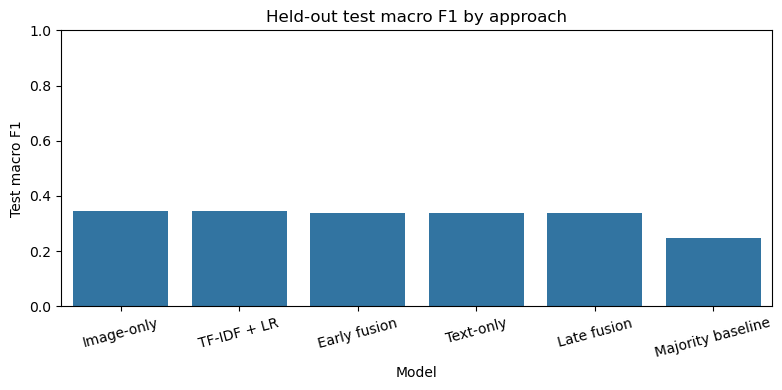

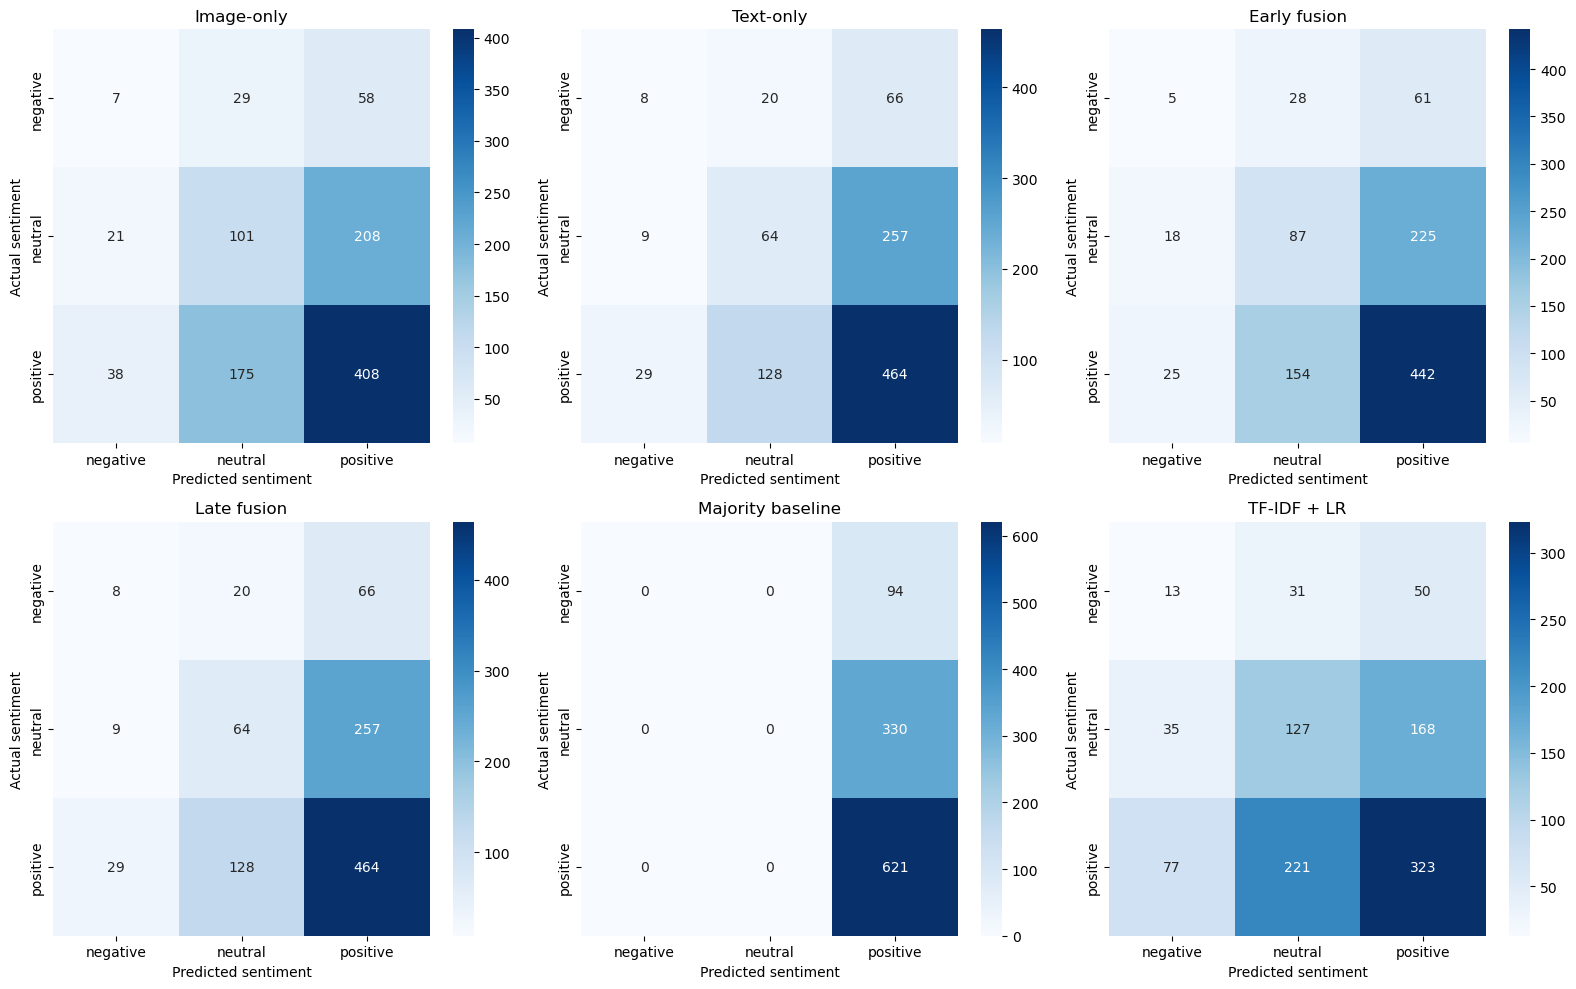

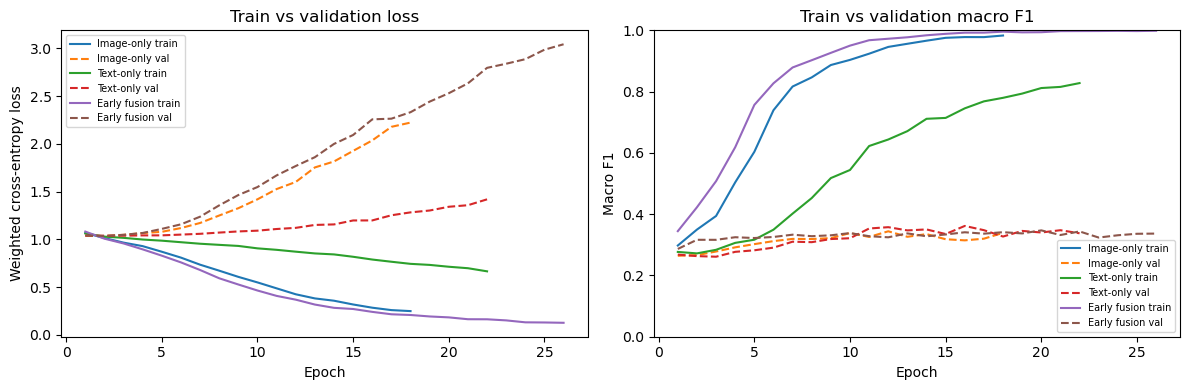

In [27]:
fig,ax=plt.subplots(figsize=(8,4))
sns.barplot(data=results,x='model',y='macro_f1',order=results.model.tolist(),ax=ax)
ax.set(xlabel='Model',ylabel='Test macro F1',title='Held-out test macro F1 by approach',ylim=(0,1))
ax.tick_params(axis='x',rotation=15)
plt.tight_layout();plt.savefig(OUTPUT_DIR/'test_macro_f1_comparison.png',dpi=200);plt.show()


# Confusion matrices for all six models
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, (name, probs) in zip(axes.flat, test_probs.items()):

    cm = confusion_matrix(
        test_truth,
        probs.argmax(axis=1),
        labels=np.arange(3)
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=LABEL_NAMES,
        yticklabels=LABEL_NAMES,
        ax=ax
    )

    ax.set(
        title=name,
        xlabel="Predicted sentiment",
        ylabel="Actual sentiment"
    )

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "confusion_matrices.png",
    dpi=200
)
plt.show()


fig,axes=plt.subplots(1,2,figsize=(12,4))
for name,h in histories.items():
    axes[0].plot(h.epoch,h.train_loss,label=f'{name} train')
    axes[0].plot(h.epoch,h.val_loss,linestyle='--',label=f'{name} val')
    axes[1].plot(h.epoch,h.train_macro_f1,label=f'{name} train')
    axes[1].plot(h.epoch,h.val_macro_f1,linestyle='--',label=f'{name} val')
axes[0].set(xlabel='Epoch',ylabel='Weighted cross-entropy loss',title='Train vs validation loss')
axes[1].set(xlabel='Epoch',ylabel='Macro F1',title='Train vs validation macro F1',ylim=(0,1))
for ax in axes:ax.legend(fontsize=7)
plt.tight_layout();plt.savefig(OUTPUT_DIR/'training_curves.png',dpi=200);plt.show()

Best test macro F1: Image-only. Misclassified test samples: 529 / 1045


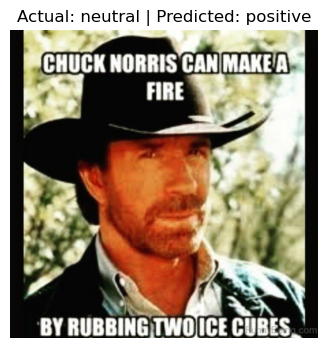

Extracted text: CHUCK NORRIS CAN MAKE A FIRE BY RUBBING TWO ICE CUBES.COM 



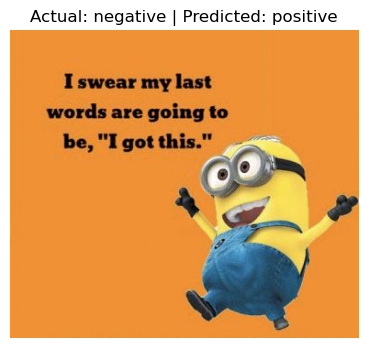

Extracted text: I swear my last words are going to be "I got this." 



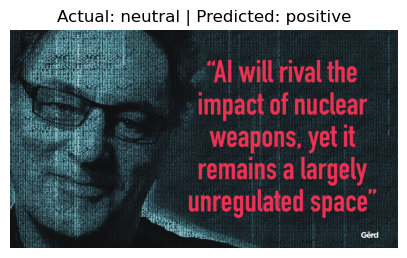

Extracted text: Al will rival the impact of nuclear weapons  yet it remains a largely unregulated space Gerd 



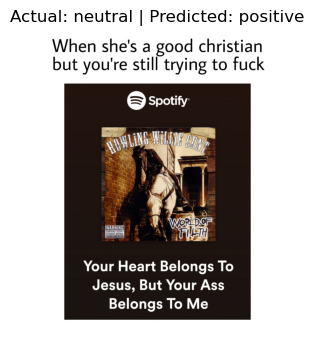

Extracted text: When she's a good christian but you're still trying to fuck Spotify WORLD OF WARNING CONTAINS OLEPLY OFFENSIVE WATERIAL Your Heart Belongs To Jesus  but your ass belongs to me 



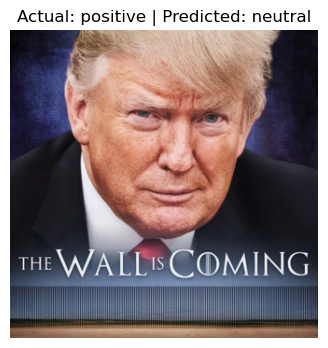

Extracted text: THE WALL IS COMING 



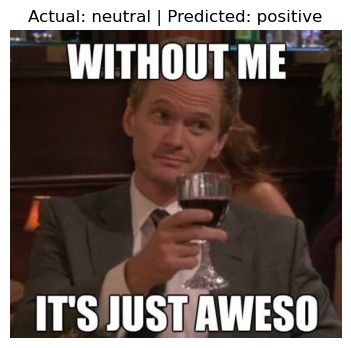

Extracted text: WITHOUT ME IT'S JUST AWESO 



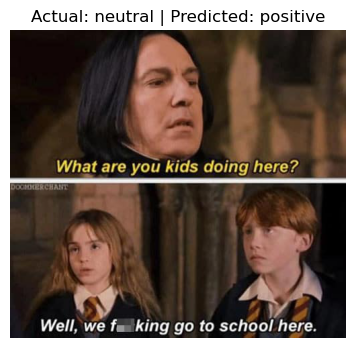

Extracted text: What are you kids doing here? DOCICERCHANT Well  we fking go to school here. 



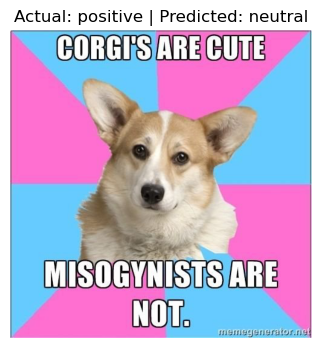

Extracted text: CORGI'S ARE CUTE MISOGYNISTS ARE NOT. memegenerator.net 

Discuss which errors involve OCR defects, irony/sarcasm, image-text mismatch or ambiguous sentiment.


In [28]:
winning_model=results.iloc[0]['model']
pred=test_probs[winning_model].argmax(axis=1)
error_locations=np.where(pred!=test_truth)[0]
print(f'Best test macro F1: {winning_model}. Misclassified test samples: {len(error_locations)} / {len(test_idx)}')
# Show a fixed first sample of incorrect predictions; don't select hyperparameters using these examples.
for local_i in error_locations[:8]:
    r=df.iloc[test_idx[local_i]]
    fig,ax=plt.subplots(figsize=(5,4))
    with Image.open(r.image_path) as im: ax.imshow(im.convert('RGB'))
    ax.axis('off');ax.set_title(f'Actual: {LABEL_NAMES[test_truth[local_i]]} | Predicted: {LABEL_NAMES[pred[local_i]]}')
    plt.show()
    print('Extracted text:',str(r.text)[:500],'\n')

print('Discuss which errors involve OCR defects, irony/sarcasm, image-text mismatch or ambiguous sentiment.')

## 11. Uncertainty in the comparison

I use paired bootstrap samples of the test predictions to estimate how much the macro F1 difference between fusion and text-only could vary. These intervals reflect uncertainty from the test examples; they do not capture variation from retraining with different random seeds.


In [30]:
def paired_bootstrap_difference(probs_a,probs_b,y_true,iterations=1000,seed=SEED):
    rng=np.random.default_rng(seed); n=len(y_true)
    pa=probs_a.argmax(1); pb=probs_b.argmax(1)
    differences=[]
    for _ in range(iterations):
        sample=rng.integers(0,n,n)
        differences.append(f1_score(y_true[sample],pa[sample],average='macro',zero_division=0)-
                           f1_score(y_true[sample],pb[sample],average='macro',zero_division=0))
    return np.percentile(differences,[2.5,50,97.5])
for name in ('Early fusion','Late fusion'):
    ci=paired_bootstrap_difference(test_probs[name],test_probs['Text-only'],test_truth)
    print(f'{name} minus text-only macro-F1 (bootstrap 2.5/50/97.5 percentiles):',np.round(ci,4))

Early fusion minus text-only macro-F1 (bootstrap 2.5/50/97.5 percentiles): [-0.036   0.0024  0.0391]
Late fusion minus text-only macro-F1 (bootstrap 2.5/50/97.5 percentiles): [0. 0. 0.]


## 12. Saving the experiment settings

I save the dataset details, model settings, selected epochs and software version alongside the results. This helps make the experiments easier to check and reproduce.


In [32]:
config = {
  'dataset': 'Memotion Dataset 7K (Kaggle: williamscott701/memotion-dataset-7k)',
  'label_mapping': label_map, 'classes': LABEL_NAMES,'seed':SEED,
  'num_examples_after_cleaning':len(df),
  'split_counts':df['split'].value_counts().to_dict(),
  'image_encoder':'torchvision ResNet-50 DEFAULT/ImageNet weights, frozen, 2048-dimensional features',
  'text_encoder':TEXT_MODEL_ID+' (frozen, masked mean pooled 768-dimensional features)',
  'text_max_tokens':MAX_TEXT_LENGTH,'image_feature_dim':Xi.shape[1],
  'text_feature_dim':Xt.shape[1], 'optimizer':'AdamW','learning_rate':3e-4,
  'weight_decay':5e-3,'hidden_layer_sizes':[128,32],'dropout':0.40,
  'epoch_limit':EPOCHS,'early_stopping_patience':PATIENCE,
  'class_weighting':'square-root inverse-frequency cross entropy (training split)',
  'late_fusion_image_weight':BEST_ALPHA,
  'best_validation_epochs': {k: int(v['best_epoch'])for k, v in training_info.items()if 'best_epoch' in v},
  'device':str(DEVICE),'torch_version':torch.__version__,
  'evaluation':'held-out single test set; macro F1 primary',
  'warning':'head training times exclude encoder embedding computation and downloads'
}
(OUTPUT_DIR/'experiment_config.json').write_text(json.dumps(config,indent=2),encoding='utf-8')
print('Files saved to:', OUTPUT_DIR.resolve())
print('Before submitting: write up actual data-quality observations, early/late fusion tradeoffs,')
print('class-level errors, runtime/memory caveats, ethics/bias considerations, references, and limitations.')

Files saved to: C:\Users\joech\Downloads\outputs_final
Before submitting: write up actual data-quality observations, early/late fusion tradeoffs,
class-level errors, runtime/memory caveats, ethics/bias considerations, references, and limitations.


## 13. Discussion and limitations

The main question is whether combining image and text improves sentiment prediction. The results show that fusion did not consistently outperform the individual models. Image-only and TF-IDF with Logistic Regression were competitive with the fusion approaches on test macro F1.

Class imbalance is an important limitation: negative memes are much less common than positive ones. The models also show a large gap between training and validation performance, particularly for early fusion. Early stopping helps choose a checkpoint, but does not remove overfitting.

Some memes depend on sarcasm, shared cultural knowledge or text that OCR does not capture well. Different people may also disagree on a meme's sentiment. These models should therefore be treated as experimental classifiers, not as reliable tools for judging people or online content without review.

The feature extractors were kept frozen to make training practical on a local GPU. This limits how much the representations can adapt to memes. A useful next step would be partial encoder fine-tuning, along with further checks of duplicate images and more runs with different seeds.

### Sources to cite in the report

- Sharma et al. (2020), *SemEval-2020 Task 8: Memotion Analysis — The Visuo-Lingual Metaphor!* — dataset and task.
- He et al. (2016), *Deep Residual Learning for Image Recognition* — ResNet.
- Sanh et al. (2019), *DistilBERT, a distilled version of BERT: smaller, faster, cheaper and lighter* — text encoder.
- Paszke et al. (2019), *PyTorch: An Imperative Style, High-Performance Deep Learning Library* — implementation library.

The full methodology, results, ethics assessment and references belong in the separate written report.
